# 01. 모델 구조의 흐름 — v1에서 3.5까지 한 표로

버전별 폴더의 노트북은 버전 하나를 깊게 봅니다. 이 노트북은 거꾸로 같은 과일 표 하나를 v1, v2, 2.5, 3, 3.5의 실제 크기 모델에 차례로 넣고, 모델 구조라는 축 하나만 따라갑니다. 토큰 하나가 무엇인지, Transformer 층이 받는 텐서가 어떤 모양인지, feature와 행이 늘면 계산이 어떻게 늘어나는지를 다섯 모델에서 나란히 봅니다.

한 줄로 요약하면 이렇습니다. v1은 행 하나가 토큰 하나였고, v2는 셀 단위 토큰으로 바꿔 feature 수 제한을 없앤 대신 계산이 행·열·학습 행의 곱으로 커졌습니다. 2.5는 그 구조를 키웠고, 3은 셀 정보를 앞쪽 블록에서 행 벡터로 압축한 뒤 v1처럼 행 단위로 24층 ICL을 해서 계산을 다시 줄였습니다. 3.5는 3의 행 벡터를 두 배로 넓혔습니다.

각 칸의 자세한 설명은 [노트북 로드맵의 버전 비교 표](../README.md#tabpfn-버전-비교)와 축별로 보기 표에서 이어지는 버전별 노트북에 있습니다. 모델은 모두 학습하지 않은 무작위 가중치입니다. 여기서는 출력값이 아니라 모양과 계산량만 봅니다.

다루는 흐름:

1. 다섯 모델 만들기 — 파라미터가 어디에 있나
2. 토큰 하나는 무엇인가 — Transformer 층이 받는 모양
3. 계산은 어디에 드나 — attention 연산량
4. 실제로 재 보기 — CPU forward 시간
5. 정리

## `minipfn` 불러오기

다른 노트북과 같은 import shim입니다. 이 노트북은 `notebooks/axes/` 아래에 있으므로 저장소 루트는 두 단계 위입니다.

In [1]:
try:
    import minipfn
except ImportError:
    import sys
    from pathlib import Path

    sys.path.insert(0, str(Path.cwd().parents[1] / "src"))
    import minipfn

In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import display

from minipfn import set_seed
from minipfn.models.row_transformer import RowTransformer
from minipfn.recipes import tabpfn_v1, tabpfn_v2, tabpfn_v3

set_seed(0)  # 재현성을 위해 난수 시드를 고정한다.

## 1. 다섯 모델 만들기 — 파라미터가 어디에 있나

버전마다 이 저장소가 학습에 쓰는 설정 그대로 모델을 만듭니다. v1은 `recipes/tabpfn_v1.py`의 `PAPER_MODEL`, v2·2.5는 `recipes/tabpfn_v2.py`의 `paper`와 `with_architecture`, 3·3.5는 `recipes/tabpfn_v3.py`의 `paper`입니다. 3.5는 이 저장소가 학습하는 분류·회귀 한 모델(`multitask`)이고, 나머지는 분류 모델입니다.

In [3]:
models = {
    "v1": RowTransformer(**tabpfn_v1.PAPER_MODEL),
    "v2": tabpfn_v2.paper("classification").build_model(),
    "v2.5": tabpfn_v2.with_architecture(tabpfn_v2.paper("classification"), "v2.5").build_model(),
    "v3": tabpfn_v3.paper("classification", "v3").build_model(),
    "v3.5": tabpfn_v3.paper("multitask", "v3.5").build_model(),
}
for model in models.values():
    model.eval()

# 모델의 맨 앞 이름을 네 부분으로 묶는다
PART = {
    # 입력: 셀·행 값과 정답을 토큰으로
    "x_encoder": "입력 encoder",
    "y_encoder": "입력 encoder",
    "feature_embedder": "입력 encoder",
    "target_embedder": "입력 encoder",
    "column_embedder": "입력 encoder",
    "thinking_rows": "입력 encoder",
    "cell_encoder": "입력 encoder",
    "cell_target": "입력 encoder",
    "cell_target_norm": "입력 encoder",
    # 3·3.5만: 셀 토큰을 행 벡터로 압축하는 앞쪽 블록
    "column_blocks": "열·행 단계",
    "cls_tokens": "열·행 단계",
    "row_blocks": "열·행 단계",
    "row_norm": "열·행 단계",
    # 층을 쌓은 본체: v1 행 Transformer, v2·2.5 2방향 층, 3·3.5 행 ICL
    "layers": "본체 층",
    "icl_target": "본체 층",
    "icl_target_norm": "본체 층",
    "icl_layers": "본체 층",
    "icl_norm": "본체 층",
    # 출력
    "decoder": "출력",
    "pre_head": "출력",
    "heads": "출력",
}

param_rows = {}
for name, model in models.items():
    counts = dict.fromkeys(["입력 encoder", "열·행 단계", "본체 층", "출력"], 0)
    for param_name, p in model.named_parameters():
        counts[PART[param_name.split(".")[0]]] += p.numel()
    counts["합계"] = sum(counts.values())
    param_rows[f"{name} ({type(model).__name__})"] = {k: v / 1e6 for k, v in counts.items()}
display(pd.DataFrame(param_rows).T.round(2).style.format("{:.2f}M"))

,입력 encoder,열·행 단계,본체 층,출력,합계
v1 (RowTransformer),0.05M,0.00M,25.23M,0.54M,25.82M
v2 (CellTransformer),0.01M,0.00M,7.08M,0.16M,7.24M
v2.5 (CellTransformer),0.02M,0.00M,14.16M,0.16M,14.34M
v3 (ColumnRowTransformer),0.00M,1.26M,51.36M,0.43M,53.06M
v3.5 (ColumnRowTransformer),0.03M,1.27M,203.19M,14.34M,218.83M


파라미터는 어느 버전이든 대부분 본체 층에 있습니다. 차이는 본체 층의 폭(embedding dim)과 층 수에서 납니다. v1은 폭 512인 층 12개, v2는 폭 192인 층 12개, 2.5는 같은 폭으로 24층, 3은 폭 512인 행 ICL 24층, 3.5는 폭 1,024인 행 ICL 24층입니다. 층 하나의 파라미터는 폭의 제곱에 비례해서, 폭이 두 배인 3.5는 3보다 본체 층이 네 배 큽니다.

3·3.5에만 있는 열·행 단계는 둘 다 1.3M쯤으로 작습니다. 셀 정보를 행 벡터로 압축하는 일은 폭 128의 블록 6개(열 3 + 행 3)로 충분하다는 설계입니다. 3.5의 출력이 큰 것은 분류와 회귀의 출력층을 둘 다 갖고 있어서이고, 회귀 출력층이 bar 구간 5,000개의 logit을 냅니다.

## 2. 토큰 하나는 무엇인가 — Transformer 층이 받는 모양

feature 5개, 학습 행 4개(사과 2, 배 2), 테스트 행 2개인 과일 표입니다. 버전별 노트북에서 쓴 것과 같습니다.

In [4]:
fruit = pd.DataFrame(
    {
        "무게(g)": [210, 190, 320, 290, 200, 310],
        "당도(brix)": [13.5, 14.0, 11.0, 11.5, 13.0, 12.0],
        "지름(cm)": [7.5, 7.2, 9.0, 8.6, 7.4, 8.8],
        "산도(pH)": [3.4, 3.5, 3.9, 3.8, 3.4, 3.9],
        "껍질(mm)": [0.6, 0.5, 1.0, 0.9, 0.6, 1.0],
    }
)
n_train = 4
shown = fruit.copy()
shown["y"] = ["0 (사과)", "0 (사과)", "1 (배)", "1 (배)", "?", "?"]
shown.index = ["학습 1", "학습 2", "학습 3", "학습 4", "테스트 5", "테스트 6"]
display(shown)

# (데이터셋 1, 행 6, feature 5)
x = torch.tensor(fruit.to_numpy(dtype=float), dtype=torch.float32)[None]
y_train = torch.tensor([0.0, 0.0, 1.0, 1.0])[None]  # (데이터셋 1, 학습 행 4)

,무게(g),당도(brix),지름(cm),산도(pH),껍질(mm),y
학습 1,210,13.5,7.5,3.4,0.6,0 (사과)
학습 2,190,14.0,7.2,3.5,0.5,0 (사과)
학습 3,320,11.0,9.0,3.9,1.0,1 (배)
학습 4,290,11.5,8.6,3.8,0.9,1 (배)
테스트 5,200,13.0,7.4,3.4,0.6,?
테스트 6,310,12.0,8.8,3.9,1.0,?


v1만 입력을 따로 준비합니다. v1은 모델 안에서 표준화하지 않고, 행 하나를 feature 100개짜리 벡터로 받습니다. 그래서 학습 행으로 표준화한 뒤 나머지 95열을 0으로 채우고, 쓴 열이 적은 만큼 $100/5$배 합니다(v1 추론 전처리와 같습니다). v2부터는 표준화를 모델 안에서 하므로 원래 값을 그대로 넣습니다.

모델마다 본체 층의 첫 층에 hook을 달아 들어가는 텐서의 모양을 꺼냅니다. 3·3.5는 열 단계, 행 단계, 행 ICL의 첫 블록 세 곳에 답니다.

In [5]:
def v1_input(x, n_train, num_features=100):
    # 학습 행으로 표준화하고, 0으로 채운 뒤 쓴 열이 적은 만큼 키운다 (v1 전처리)
    mean = x[:, :n_train].mean(1, keepdim=True)
    std = x[:, :n_train].std(1, unbiased=False, keepdim=True)
    z = (x - mean) / std
    return F.pad(z, (0, num_features - x.shape[-1])) * (num_features / x.shape[-1])


def run(name, model, x, y_train):
    n = y_train.shape[1]
    if name == "v1":
        xp = v1_input(x, n)
        return model(xp[:, :n], y_train, xp[:, n:])
    if name == "v3.5":
        return model(x, y_train, task="classification")
    return model(x, y_train)


THREE_STAGES = [
    ("열 단계", "column_blocks"),
    ("행 단계", "row_blocks"),
    ("본체 층 (행 ICL)", "icl_layers"),
]
HOOK_POINTS = {
    "v1": [("본체 층", "layers")],
    "v2": [("본체 층", "layers")],
    "v2.5": [("본체 층", "layers")],
    "v3": THREE_STAGES,
    "v3.5": THREE_STAGES,
}

shapes = []
for name, model in models.items():
    captured, hooks = {}, []
    for stage, attr in HOOK_POINTS[name]:
        first = getattr(model, attr)[0]
        hooks.append(
            first.register_forward_pre_hook(
                lambda module, inputs, stage=stage, captured=captured: captured.update(
                    {stage: tuple(inputs[0].shape)}
                )
            )
        )
    with torch.no_grad():
        out = run(name, model, x, y_train)
    for hook in hooks:
        hook.remove()
    for stage, shape in captured.items():
        shapes.append({"모델": name, "단계": stage, "입력 모양": str(shape)})
    output = {"모델": name, "단계": "출력 (테스트 행 logit)", "입력 모양": str(tuple(out.shape))}
    shapes.append(output)
display(pd.DataFrame(shapes).set_index(["모델", "단계"]))

입력 모양
모델   단계                               
v1   본체 층                  (1, 6, 512)
     출력 (테스트 행 logit)       (1, 2, 10)
v2   본체 층               (1, 6, 4, 192)
     출력 (테스트 행 logit)       (1, 2, 10)
v2.5 본체 층              (1, 70, 3, 192)
     출력 (테스트 행 logit)       (1, 2, 10)
v3   열 단계                  (5, 6, 128)
     행 단계                  (6, 9, 128)
     본체 층 (행 ICL)          (1, 6, 512)
     출력 (테스트 행 logit)       (1, 2, 10)
v3.5 열 단계                  (5, 6, 128)
     행 단계                 (6, 13, 128)
     본체 층 (행 ICL)         (1, 6, 1024)
     출력 (테스트 행 logit)       (1, 2, 10)

모양을 하나씩 읽으면 토큰이 무엇인지 보입니다.

- **v1 (1, 6, 512)**: 행 6개가 토큰 6개입니다. 행 하나의 feature 100칸이 Linear 하나로 512차원 벡터가 되고, 학습 행에는 정답 embedding이 더해집니다. 본체 층은 행끼리만 attention합니다. 열이 텐서 모양에 없으니 feature가 몇 개든 계산은 같지만, 입력 Linear가 100칸에 묶여 있어 feature 100개를 넘는 표는 받지 못합니다.
- **v2 (1, 6, 4, 192)**: 행 6개 × 토큰 4개입니다. feature 5개를 2개씩 묶어 3묶음(마지막 묶음은 빈 칸 하나를 0으로 채움)에 y 토큰 하나를 더한 것입니다. 층마다 같은 행의 토큰끼리(feature attention), 같은 열의 토큰끼리(sample attention) 번갈아 봅니다. 열이 텐서 모양에 들어오면서 feature 수 제한이 없어졌습니다.
- **v2.5 (1, 70, 3, 192)**: 행이 70개인 것은 학습되는 thinking 행 64개가 맨 앞에 붙어서이고, 토큰이 3개인 것은 셀을 3개씩 묶어 2묶음 + y 토큰이어서입니다. 모양은 v2와 같은 4차원이고 층만 두 배입니다.
- **v3 열 단계 (5, 6, 128)**: 열 5개가 따로따로 돕니다. 열 하나에서 행 6개가 토큰입니다.
- **v3 행 단계 (6, 9, 128)**: 이번에는 행 6개가 따로따로 돌고, 행 하나에서 CLS 4개 + feature 5개 = 9개가 토큰입니다.
- **v3 본체 층 (1, 6, 512)**: CLS 4개의 출력을 이어 붙여 행 하나가 512차원 벡터 하나가 됩니다. 모양이 v1과 같습니다. 셀 정보를 앞쪽 블록에서 행 벡터로 압축한 뒤, v1처럼 행끼리 in-context learning을 하는 것입니다.
- **v3.5**: 모양 흐름은 3과 같고, CLS가 8개라 행 단계 토큰이 13개, 행 벡터가 1,024차원입니다.

출력은 다섯 모델 모두 (1, 2, 10), 곧 테스트 행 2개마다 클래스 상한 10개의 logit입니다. 토큰을 만드는 방식은 달라도 "학습 행과 정답을 보고 테스트 행의 분포를 낸다"는 PFN의 입출력은 그대로입니다.

## 3. 계산은 어디에 드나 — attention 연산량

2절의 모양에서 층마다 attention 점수(query와 key의 내적)가 몇 개인지 셉니다. 행 $R$개, 학습 행 $N$개, feature $F$개입니다. 점수 하나를 계산하는 비용은 폭(embedding dim)에 비례하므로, 점수 개수에 그 단계의 폭을 곱한 값을 attention 연산량으로 봅니다. MLP는 뺍니다.

- v1: 모든 행이 학습 행을 봅니다. 층마다 $R \cdot N$, 폭 512, 12층
- v2: 토큰 열 $C = \lceil F/2 \rceil + 1$개. 층마다 feature attention $R \cdot C^2$와 sample attention $C \cdot R \cdot N$, 폭 192, 12층
- 2.5: $C = \lceil F/3 \rceil + 1$, thinking 행 64개가 행과 학습 행에 더해지고, 24층
- 3·3.5: 열 단계 $3 \cdot F \cdot M \cdot (N + R)$($M$ = inducing point 128개)와 행 단계 (마지막 블록은 CLS만 query)는 폭 128, 행 ICL $24 \cdot R \cdot N$은 폭 512(3) 또는 1,024(3.5)

In [6]:
def attention_cost(name, rows, n_train, n_features):
    # 점수 개수 × 그 단계의 폭. v1은 feature 100개까지만 받는다
    if name == "v1":
        return np.nan if n_features > 100 else 12 * rows * n_train * 512
    if name in ("v2", "v2.5"):
        group, layers, thinking = (2, 12, 0) if name == "v2" else (3, 24, 64)
        c = -(-n_features // group) + 1  # 셀 묶음 + y 토큰
        r, n = rows + thinking, n_train + thinking
        return layers * (r * c * c + c * r * n) * 192
    k, icl_width = (4, 512) if name == "v3" else (8, 1024)
    tokens = k + n_features
    column = 3 * n_features * 128 * (n_train + rows)
    row = 2 * rows * tokens**2 + rows * k * tokens  # 마지막 블록은 CLS만 query
    icl = 24 * rows * n_train
    return (column + row) * 128 + icl * icl_width


sizes = [(1_000, 10), (1_000, 100), (10_000, 100), (10_000, 500), (100_000, 100), (10_000, 2_000)]
cost = {}
for rows, n_features in sizes:
    n_train = int(rows * 0.8)
    cost[(rows, n_features)] = {
        name: attention_cost(name, rows, n_train, n_features) / 1e12 for name in models
    }
cost_table = pd.DataFrame(cost).T.rename_axis(["행 수", "feature 수"])
print("attention 연산량 (단위: 1조, v1은 feature 100개까지만)")
display(cost_table.round(3))

attention 연산량 (단위: 1조, v1은 feature 100개까지만)


v1       v2      v2.5      v3     v3.5
행 수    feature 수                                            
1000   10          0.005    0.011     0.021   0.011    0.021
       100         0.005    0.100     0.154   0.021    0.032
10000  100         0.492    9.460    13.146   1.100    2.086
       500           NaN   47.716    64.135   2.078    3.074
100000 100        49.152  940.631  1292.663  99.471  197.802
10000  2000          NaN  207.590   270.504  13.044   14.078

작은 표(행 1,000개, feature 10개)에서는 v1이 가장 쌉니다. 행 수만큼만 토큰이 있고 열 방향 attention이 없기 때문입니다. feature가 10배가 되면 v2는 연산량이 9배, 2.5는 7배가 됩니다. sample attention $C \cdot R \cdot N$이 토큰 열 $C$마다 반복되기 때문입니다. 행과 feature가 함께 커지면(행 10만 개, feature 100개) v2는 v1의 19배, 2.5는 26배가 됩니다.

3·3.5는 다시 v1 쪽으로 돌아옵니다. 24층짜리 행 ICL이 feature 수와 상관없는 $R \cdot N$이라, 행 10만 개, feature 100개에서 3은 2.5의 13분의 1이고 v1의 두 배쯤입니다. 3.5는 행 ICL의 폭이 두 배라 3의 두 배쯤 들지만, 그래도 2.5의 7분의 1쯤입니다. feature가 아주 많은 표(2,000개)에서는 3·3.5도 행 단계의 $(k + F)^2$ 때문에 늘지만, 블록이 3개뿐이라 24층 내내 열 방향 attention을 하는 2.5보다 적습니다.

행 1만 개에서 feature 수를 바꾸며 그리면 이 차이가 한눈에 보입니다.

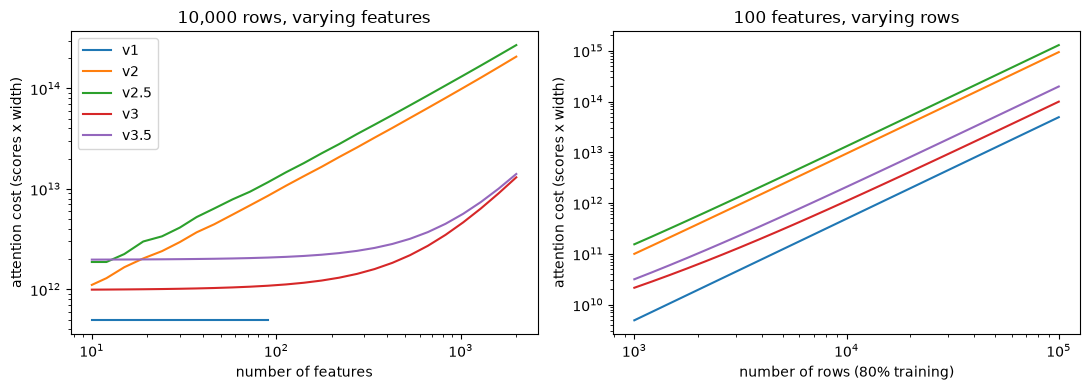

In [7]:
feature_grid = np.unique(np.logspace(1, np.log10(2_000), 25).astype(int))
row_grid = np.unique(np.logspace(3, 5, 25).astype(int))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name in models:
    by_features = [attention_cost(name, 10_000, 8_000, f) for f in feature_grid]
    by_rows = [attention_cost(name, r, int(r * 0.8), 100) for r in row_grid]
    axes[0].plot(feature_grid, by_features, label=name)
    axes[1].plot(row_grid, by_rows, label=name)
axes[0].set_title("10,000 rows, varying features")
axes[0].set_xlabel("number of features")
axes[1].set_title("100 features, varying rows")
axes[1].set_xlabel("number of rows (80% training)")
for ax in axes:
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_ylabel("attention cost (scores x width)")
axes[0].legend()
plt.tight_layout()
plt.show()

왼쪽 그림에서 v1의 선은 feature 100개에서 끝납니다. 입력 Linear가 100칸이라 그 너머는 받지 못합니다. v2·2.5의 선은 feature에 비례해 올라가고, 3·3.5의 선은 feature가 수백 개가 될 때까지 천천히 오르다가 행 단계가 커지면서 가팔라집니다. 오른쪽 그림에서는 다섯 모델 모두 행 수의 제곱으로 늘지만($R \cdot N$), v2·2.5는 그 앞에 토큰 열 수가 곱해져 있어서 선이 위에 있습니다.

## 4. 실제로 재 보기 — CPU forward 시간

연산량 표가 실제 시간과 같은 방향인지 CPU에서 재 봅니다. 학습 행 80%, 테스트 행 20%인 분류 표이고, 세 번 재서 가운데 값을 씁니다. MLP와 입력 encoder 시간도 들어가므로 3절의 연산량과 비율이 똑같지는 않습니다.

In [8]:
def forward_seconds(name, model, rows, n_features, repeat=3):
    n = int(rows * 0.8)
    torch.manual_seed(0)
    xb = torch.randn(1, rows, n_features)
    yb = torch.randint(0, 2, (1, n)).float()
    with torch.inference_mode():
        run(name, model, xb, yb)  # 처음 한 번은 준비로 빼고 잰다
        seconds = []
        for _ in range(repeat):
            start = time.perf_counter()
            run(name, model, xb, yb)
            seconds.append(time.perf_counter() - start)
    return float(np.median(seconds))


timing = {}
for rows, n_features in [(1024, 10), (1024, 100)]:
    timing[(rows, n_features)] = {
        name: forward_seconds(name, model, rows, n_features) for name, model in models.items()
    }
display(pd.DataFrame(timing).T.rename_axis(["행 수", "feature 수"]).round(2))

v1    v2  v2.5    v3  v3.5
행 수  feature 수                              
1024 10         0.09  0.22  0.35  0.24  0.63
     100        0.11  1.52  2.42  0.68  1.20

feature 10개에서 100개로 늘리면 v1은 그대로이고(v1은 늘 100칸을 받습니다), v2·2.5는 몇 배로 늘고, 3·3.5는 덜 늡니다. 3.5는 파라미터가 2.5의 15배인데도 feature 100개에서는 2.5보다 빠릅니다. CPU에서 잰 값이라 실행마다 조금씩 다르고 GPU와도 다를 수 있습니다.

## 5. 정리

| 모델 | 토큰 하나 | 본체 층이 받는 모양 | feature가 늘면 | 자세히 |
|---|---|---|---|---|
| v1 | 행 하나 (feature 100칸 → Linear) | (B, R, 512) | 계산은 그대로, 100개를 넘으면 못 받음 | [02_tabpfn/04](../02_tabpfn/04_tabpfn_paper_architecture.ipynb) 2절 |
| v2 | 셀 2개 묶음, 행마다 y 토큰 | (B, R, ⌈F/2⌉ + 1, 192) | 층마다 sample attention이 토큰 열 수만큼 늘어남 | [03_tabpfn_v2/01](../03_tabpfn_v2/01_cell_tokens_and_two_way_attention.ipynb)·[02](../03_tabpfn_v2/02_attention_properties_and_cost.ipynb) |
| 2.5 | 셀 3개 묶음, thinking 행 64개 | (B, 64 + R, ⌈F/3⌉ + 1, 192) | v2와 같고 층이 두 배 | [04_tabpfn_v2_5/01](../04_tabpfn_v2_5/01_layers_and_feature_groups.ipynb)·[02](../04_tabpfn_v2_5/02_thinking_rows_and_regression_encoder.ipynb) |
| 3 | 셀 3개 묶음 → 열 단계 → 행 단계에서 CLS 4개로 압축 | 열 (B·F, R, 128) → 행 (B·R, 4 + F, 128) → 본체 (B, R, 512) | 앞쪽 6블록만 늘고 24층 행 ICL은 그대로 | [05_tabpfn_v3/01](../05_tabpfn_v3/01_overview_and_cell_encoder.ipynb)·[02](../05_tabpfn_v3/02_column_row_icl_stages.ipynb) |
| 3.5 | 3과 같고 CLS 8개 | 행 (B·R, 8 + F, 128) → 본체 (B, R, 1024) | 3과 같음 | [06_tabpfn_v3_5/01](../06_tabpfn_v3_5/01_changes_and_multitask.ipynb) |

v1 → v2는 feature 수 제한을 없애려고 토큰을 셀 단위로 쪼갰고, 그 대가로 계산이 행·열·학습 행의 곱으로 커졌습니다. 2.5는 같은 구조를 키웠습니다. 3은 셀 단위 계산을 앞쪽 몇 블록으로 몰고 본체를 다시 행 단위로 되돌려, feature 수 제한 없이 v1에 가까운 계산량을 얻었습니다. 3.5는 그렇게 아낀 계산으로 행 벡터를 넓혔습니다.